# 13 - Financial and Numeric Features vs. Popularity

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent
df = pd.read_csv(PROJECT_ROOT / "data" / "features" / "09_popularity_features.csv")

columns = ["log_budget", "log_revenue", "runtime", "target_log_popularity"]
print(df.shape)
print(df[columns].describe().round(2))

(45430, 34)
       log_budget  log_revenue   runtime  target_log_popularity
count     8880.00      7398.00  43615.00               45430.00
mean        15.37        15.97     97.49                   0.98
std          2.77         3.10     34.65                   0.80
min          0.69         0.69      1.00                   0.00
25%         14.51        14.69     86.00                   0.33
50%         15.89        16.64     95.00                   0.75
75%         17.03        18.02    107.00                   1.54
max         19.76        21.75   1256.00                   6.31


## Scatter plot: log_budget vs. target_log_popularity

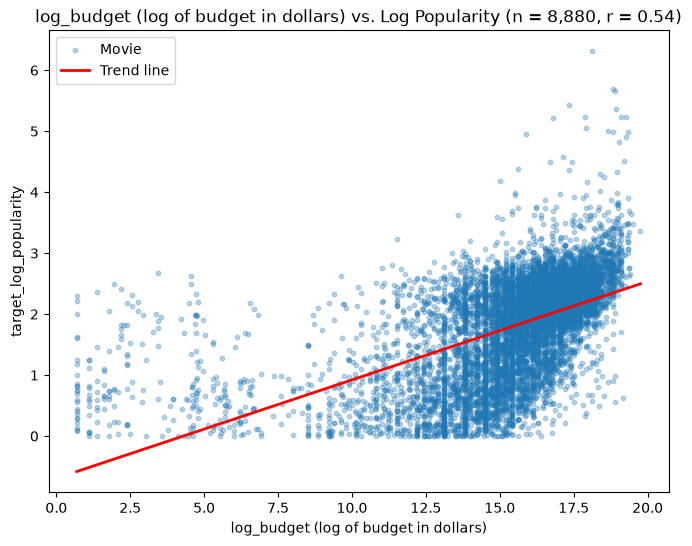

In [2]:
def scatter_plot(column, xlabel, xmax=None):
    data = df[[column, "target_log_popularity"]].dropna()
    r = data[column].corr(data["target_log_popularity"])
    slope, intercept = np.polyfit(data[column], data["target_log_popularity"], 1)
    line_x = np.array([data[column].min(), data[column].max()])

    plt.figure(figsize=(8, 6))
    plt.scatter(data[column], data["target_log_popularity"], alpha=0.3, s=10, label="Movie")
    plt.plot(line_x, slope * line_x + intercept, color="red", linewidth=2, label="Trend line")
    plt.title(f"{xlabel} vs. Log Popularity (n = {len(data):,}, r = {r:.2f})")
    plt.xlabel(xlabel)
    plt.ylabel("target_log_popularity")
    if xmax:
        plt.xlim(0, xmax)
    plt.legend()
    plt.show()


scatter_plot("log_budget", "log_budget (log of budget in dollars)")

## Scatter plot: log_revenue vs. target_log_popularity

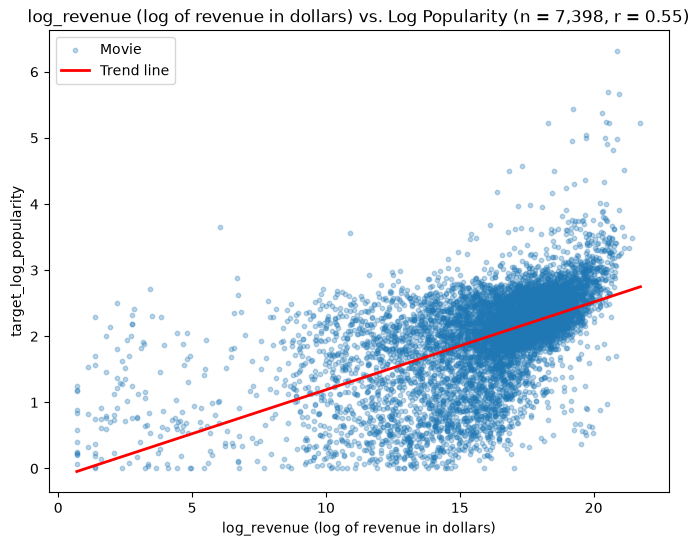

In [3]:
scatter_plot("log_revenue", "log_revenue (log of revenue in dollars)")

## Scatter plot: runtime vs. target_log_popularity

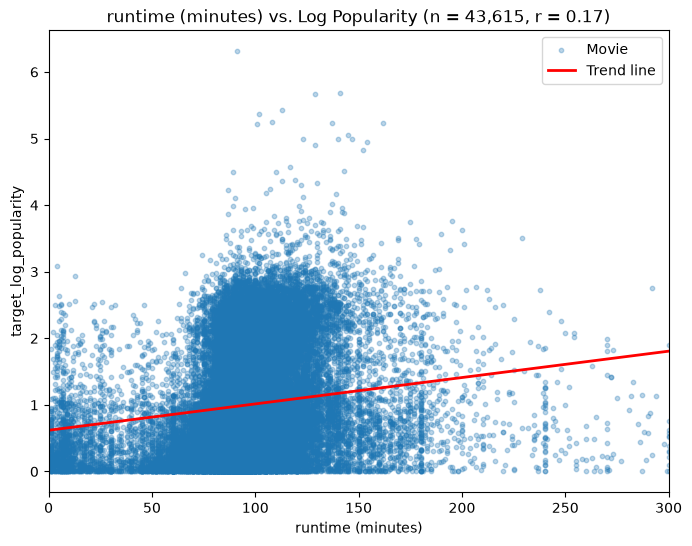

In [4]:
scatter_plot("runtime", "runtime (minutes)", xmax=300)

## Correlation heatmap

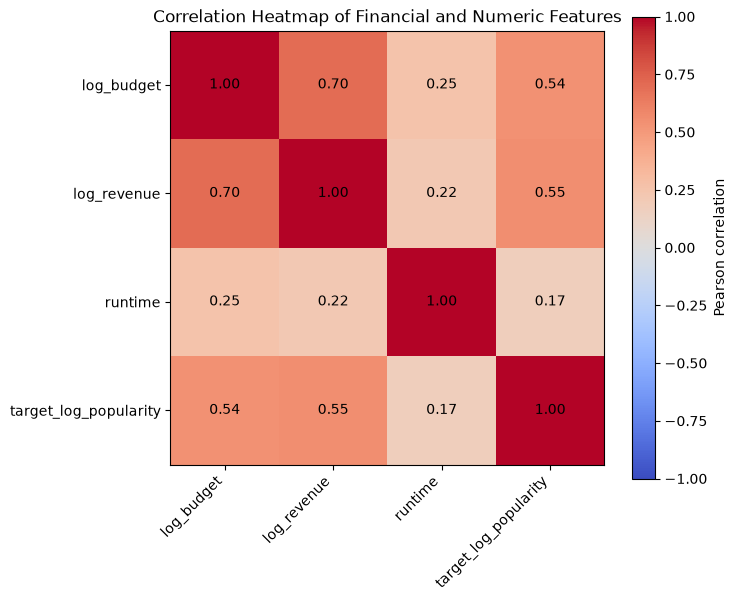

In [5]:
corr = df[columns].corr()

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(columns)))
ax.set_xticklabels(columns, rotation=45, ha="right")
ax.set_yticks(range(len(columns)))
ax.set_yticklabels(columns)
for i in range(len(columns)):
    for j in range(len(columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, label="Pearson correlation")
ax.set_title("Correlation Heatmap of Financial and Numeric Features")
plt.show()

## Distribution plot: target_log_popularity

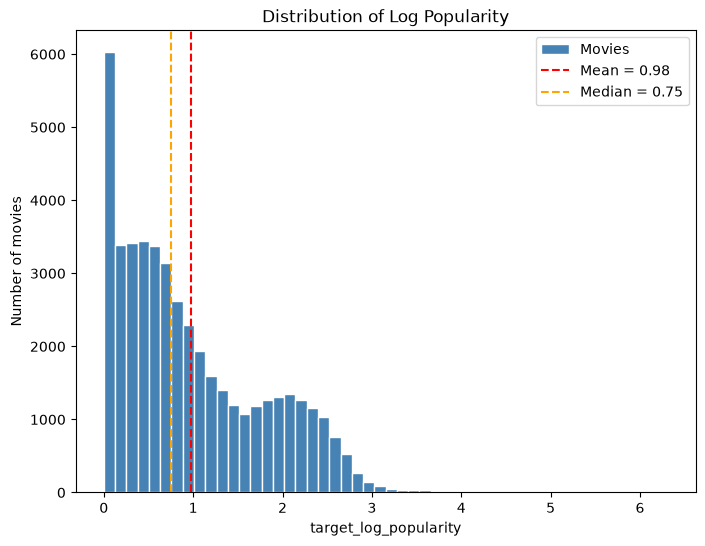

In [6]:
popularity = df["target_log_popularity"]

plt.figure(figsize=(8, 6))
plt.hist(popularity, bins=50, color="steelblue", edgecolor="white", label="Movies")
plt.axvline(popularity.mean(), color="red", linestyle="--", label=f"Mean = {popularity.mean():.2f}")
plt.axvline(popularity.median(), color="orange", linestyle="--", label=f"Median = {popularity.median():.2f}")
plt.title("Distribution of Log Popularity")
plt.xlabel("target_log_popularity")
plt.ylabel("Number of movies")
plt.legend()
plt.show()

## Extra: log_budget vs. log_revenue, colored by popularity

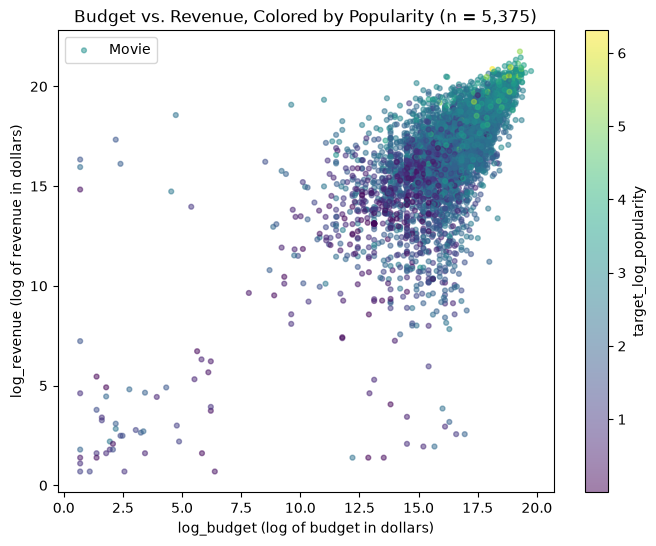

In [7]:
data = df[["log_budget", "log_revenue", "target_log_popularity"]].dropna()

plt.figure(figsize=(8, 6))
points = plt.scatter(data["log_budget"], data["log_revenue"], c=data["target_log_popularity"],
                     cmap="viridis", alpha=0.5, s=12, label="Movie")
plt.colorbar(points, label="target_log_popularity")
plt.title(f"Budget vs. Revenue, Colored by Popularity (n = {len(data):,})")
plt.xlabel("log_budget (log of budget in dollars)")
plt.ylabel("log_revenue (log of revenue in dollars)")
plt.legend()
plt.show()